# Методы обработки и распознавания изображений¶

## Практическое занятие 7: Морфологические операции

На практике переход к бинарному изображению делают не “ради бинарности”, а чтобы превратить исходное изображение в удобную маску объекта: отделить полезные области от фона, упростить структуру данных и подготовить изображение к дальнейшим операциям анализа формы, поиска контуров, OCR, подсчёта объектов и морфологической очистки. Именно поэтому после пороговой обработки почти сразу идут морфологические операции: они позволяют убрать мелкий шум, соединить разрывы, заполнить отверстия и сделать бинарную маску пригодной для дальнейшего алгоритмического анализа.

### Переход к бинарным изображениям: зачем это нужно на практике
Во многих задачах компьютерного зрения исходное изображение содержит слишком много лишней информации: цвет, текстуру, плавные перепады освещённости и шум. Для большого числа прикладных алгоритмов важен не весь спектр визуальных данных, а только факт принадлежности пикселя к объекту или фону, поэтому изображение переводят в бинарную форму, где объект выделяется белым, а фон — чёрным.

С практической точки зрения это делается в следующих ситуациях:
* При подготовке изображения к распознаванию текста, когда нужно отделить символы от фона документа.
* При сегментации объектов, когда требуется получить маску детали, клетки, дорожного знака или иного объекта.
* При поиске контуров, когда нужно выделить границы объектов на фоне.
* При подсчёте объектов на изображении, когда важна форма и площадь выделенных областей, а не их цвет.
* При предварительной очистке изображения перед анализом структуры, где после бинаризации применяются морфологические операции.

Бинаризация это промежуточный этап предобработки, после которого изображение становится более удобным для последующих процедур: выделения контуров, фильтрации связных компонентов, вычисления геометрических характеристик и морфологической коррекции. Если бинаризация выполнена некачественно, то последующие шаги также будут работать плохо, поэтому выбор метода пороговой обработки и дальнейшей морфологии имеет большой практический смысл.

### Морфологические операции
Морфологические операции — это методы обработки изображения, основанные на форме объектов. Обычно они применяются к бинарным изображениям и используют структурирующий элемент, или ядро, которое определяет характер преобразования. Базовыми морфологическими операциями являются эрозия и дилатация, а более сложные операции, такие как opening и closing, строятся как их комбинации.

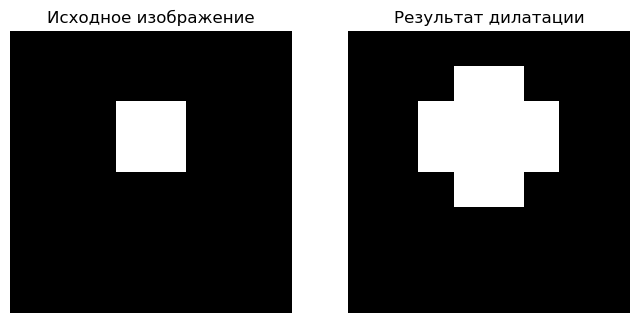

In [5]:
#Дилатация
import numpy as np
import matplotlib.pyplot as plt
from skimage.morphology import binary_dilation

# Большее бинарное изображение
binary_image = np.array([
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 1, 1, 0, 0, 0],
    [0, 0, 0, 1, 1, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0]
], dtype=np.uint8)

# Квадратный структурный элемент
selem = np.ones((1, 3))
#selem = np.ones((3, 3))

# Проведение операции дилатации
dilated_image = binary_dilation(binary_image) #selem=selem

# Визуализация обоих изображений
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(binary_image, cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Исходное изображение')
axes[1].imshow(dilated_image, cmap='gray', vmin=0, vmax=1)
axes[1].set_title('Результат дилатации')
for ax in axes:
    ax.axis('off')
plt.show()

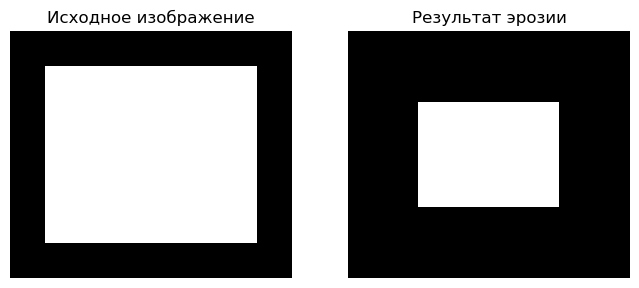

In [7]:
#Эрозия
import numpy as np
import matplotlib.pyplot as plt
from skimage.morphology import binary_erosion

# Бинарное изображение большего размера
binary_image = np.array([
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 1, 1, 0],
    [0, 1, 1, 1, 1, 1, 1, 0],
    [0, 1, 1, 1, 1, 1, 1, 0],
    [0, 1, 1, 1, 1, 1, 1, 0],
    [0, 1, 1, 1, 1, 1, 1, 0],
    [0, 0, 0, 0, 0, 0, 0, 0]
], dtype=np.uint8)

# Структурный элемент (небольшой квадрат)
selem = np.ones((3, 3))

# Применение операции эрозии
eroded_image = binary_erosion(binary_image) #selem=selem

# Визуализация изображений
fig, axes = plt.subplots(1, 2, figsize=(8, 8))
axes[0].imshow(binary_image, cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Исходное изображение')
axes[1].imshow(eroded_image, cmap='gray', vmin=0, vmax=1)
axes[1].set_title('Результат эрозии')
for ax in axes:
    ax.axis('off')
plt.show()

### 1. Подготовка данных для морфологии
Сначала создадим бинарное изображение, на котором хорошо видны шум, отверстия и разрывы. Это позволит наглядно продемонстрировать практический смысл морфологических операций.

In [1]:
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [2]:
# Морфологические операции

def create_morphology_demo_image():
    """
    Создает синтетическое бинарное изображение
    с объектами, шумом и разрывами.
    """
    img = np.zeros((220, 320), dtype=np.uint8)

    # Основные объекты
    cv2.rectangle(img, (30, 40), (120, 170), 255, -1)
    cv2.circle(img, (220, 90), 40, 255, -1)
    cv2.putText(img, "A", (180, 190),
                cv2.FONT_HERSHEY_SIMPLEX, 2, 255, 5)

    # Искусственные "дыры" в объектах
    cv2.circle(img, (70, 100), 10, 0, -1)
    cv2.rectangle(img, (210, 80), (225, 95), 0, -1)

    # Разрывы
    cv2.line(img, (30, 100), (120, 100), 0, 3)

    # Белый шум
    np.random.seed(42)
    for _ in range(120):
        x = np.random.randint(0, img.shape[1])
        y = np.random.randint(0, img.shape[0])
        img[y, x] = 255

    return img

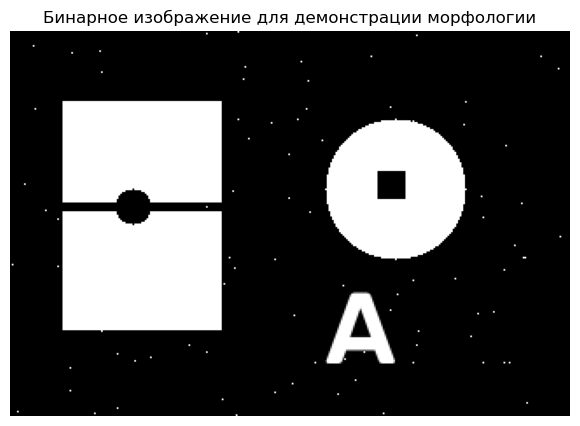

In [8]:
binary_demo = create_morphology_demo_image()

plt.figure(figsize=(8, 5))
plt.imshow(binary_demo, cmap='gray')
plt.title("Бинарное изображение для демонстрации морфологии")
plt.axis("off")
plt.show()

### 2. Структурирующий элемент
Морфологические операции зависят не только от типа операции, но и от формы ядра. В OpenCV ядро можно создать функцией `cv2.getStructuringElement`, используя прямоугольную, эллиптическую или крестообразную форму.

In [9]:
kernel_rect = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
kernel_ellipse = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
kernel_cross = cv2.getStructuringElement(cv2.MORPH_CROSS, (5, 5))

print("RECT:\n", kernel_rect)
print("\nELLIPSE:\n", kernel_ellipse)
print("\nCROSS:\n", kernel_cross)

RECT:
 [[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]

ELLIPSE:
 [[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]

CROSS:
 [[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]


### 3. Эрозия
Эрозия уменьшает белые области изображения и удаляет пиксели по границе объекта. На практике она полезна для удаления мелкого шума и разделения слипшихся объектов.

In [10]:
def demo_erosion(binary_img, kernel):
    erosion = cv2.erode(binary_img, kernel, iterations=1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(binary_img, cmap='gray')
    axes[0].set_title("Исходное бинарное")
    axes[0].axis("off")

    axes[1].imshow(erosion, cmap='gray')
    axes[1].set_title("Эрозия")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    return erosion

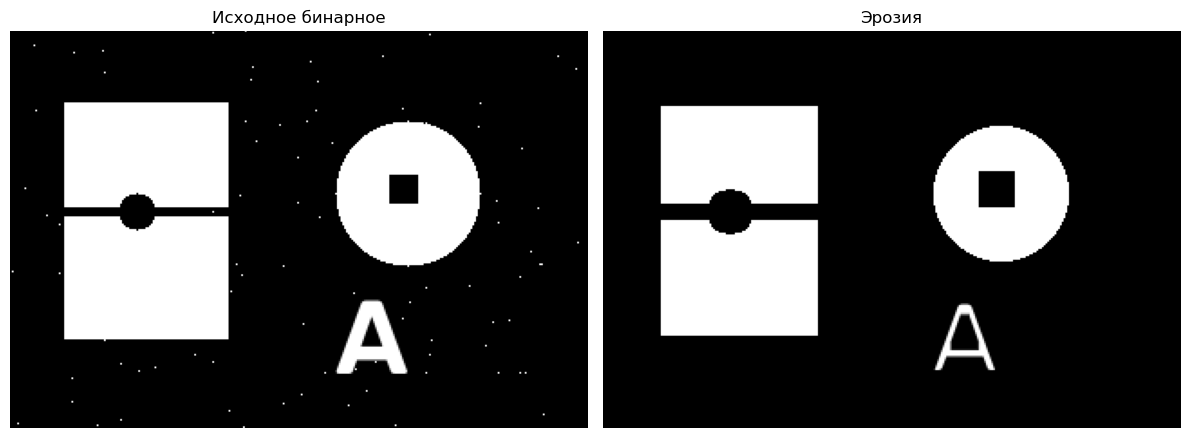

In [11]:
img_eroded = demo_erosion(binary_demo, kernel_rect)

### 4. Дилатация
Дилатация расширяет белые области изображения. Она применяется для утолщения объектов, соединения близко расположенных фрагментов и заполнения небольших промежутков.

In [12]:
def demo_dilation(binary_img, kernel):
    dilation = cv2.dilate(binary_img, kernel, iterations=1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(binary_img, cmap='gray')
    axes[0].set_title("Исходное бинарное")
    axes[0].axis("off")

    axes[1].imshow(dilation, cmap='gray')
    axes[1].set_title("Дилатация")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    return dilation

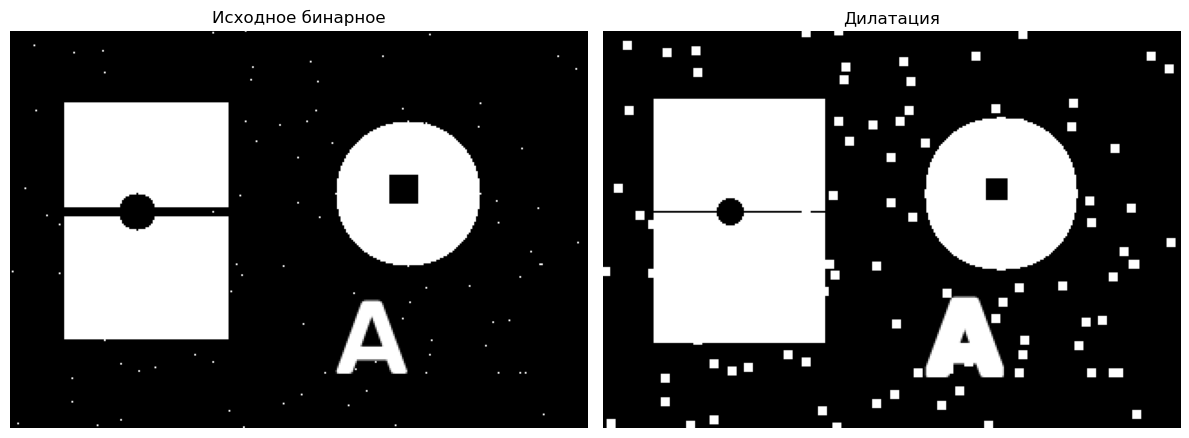

In [13]:
img_dilated = demo_dilation(binary_demo, kernel_rect)

### 5. Opening
Операция opening состоит из эрозии, за которой следует дилатация. Она обычно применяется для удаления мелких белых шумовых точек при сохранении основных объектов.

In [14]:
def demo_opening(binary_img, kernel):
    opened = cv2.morphologyEx(binary_img, cv2.MORPH_OPEN, kernel)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(binary_img, cmap='gray')
    axes[0].set_title("Исходное бинарное")
    axes[0].axis("off")

    axes[1].imshow(opened, cmap='gray')
    axes[1].set_title("Opening")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    return opened

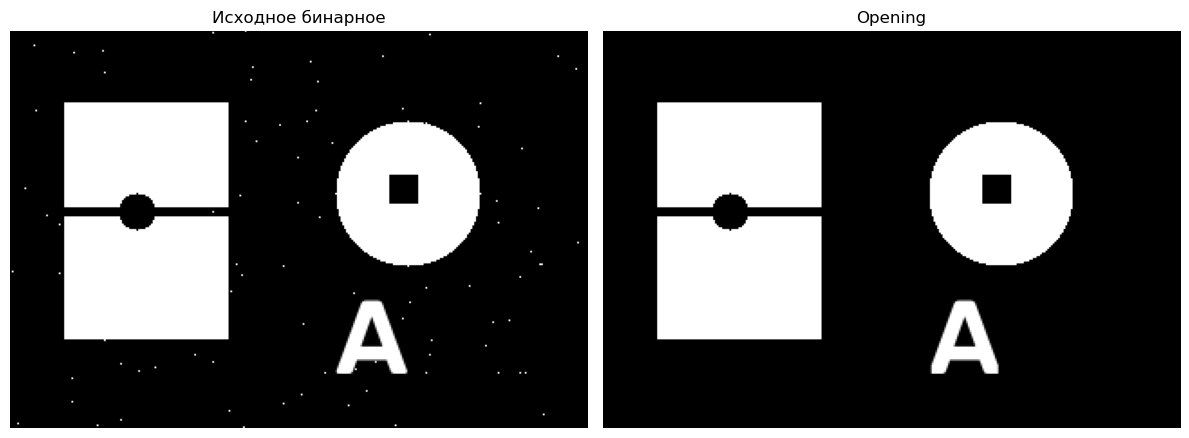

In [15]:
img_opened = demo_opening(binary_demo, kernel_rect)

### 6. Closing
Операция closing состоит из дилатации, за которой следует эрозия. Она используется для заполнения небольших отверстий и устранения разрывов внутри белых объектов.

In [16]:
def demo_closing(binary_img, kernel):
    closed = cv2.morphologyEx(binary_img, cv2.MORPH_CLOSE, kernel)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(binary_img, cmap='gray')
    axes[0].set_title("Исходное бинарное")
    axes[0].axis("off")

    axes[1].imshow(closed, cmap='gray')
    axes[1].set_title("Closing")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    return closed

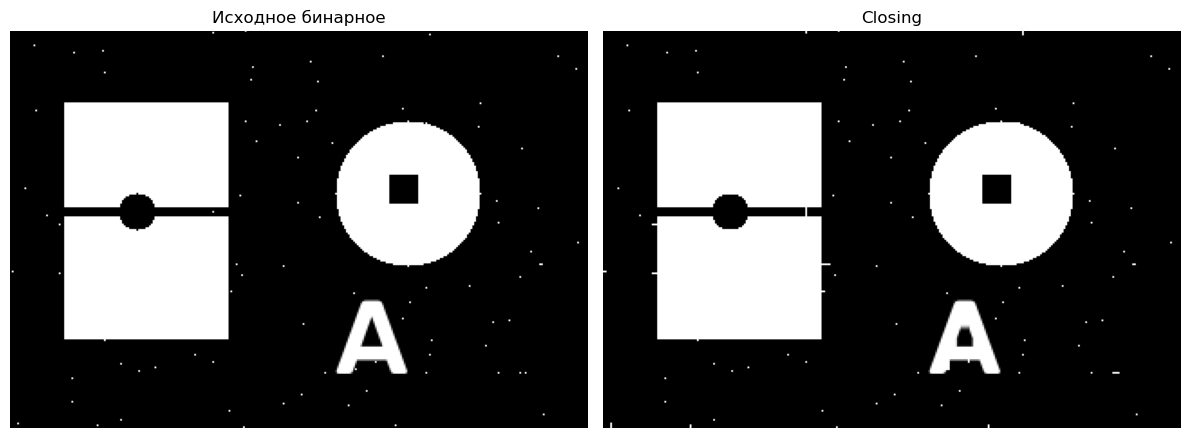

In [17]:
img_closed = demo_closing(binary_demo, kernel_rect)

### 7. Сравнение основных морфологических операций

In [18]:
def compare_morphology(binary_img, kernel):
    eroded = cv2.erode(binary_img, kernel, iterations=1)
    dilated = cv2.dilate(binary_img, kernel, iterations=1)
    opened = cv2.morphologyEx(binary_img, cv2.MORPH_OPEN, kernel)
    closed = cv2.morphologyEx(binary_img, cv2.MORPH_CLOSE, kernel)

    titles = ["Исходное", "Эрозия", "Дилатация", "Opening", "Closing"]
    images = [binary_img, eroded, dilated, opened, closed]

    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    for ax, img, title in zip(axes, images, titles):
        ax.imshow(img, cmap='gray')
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

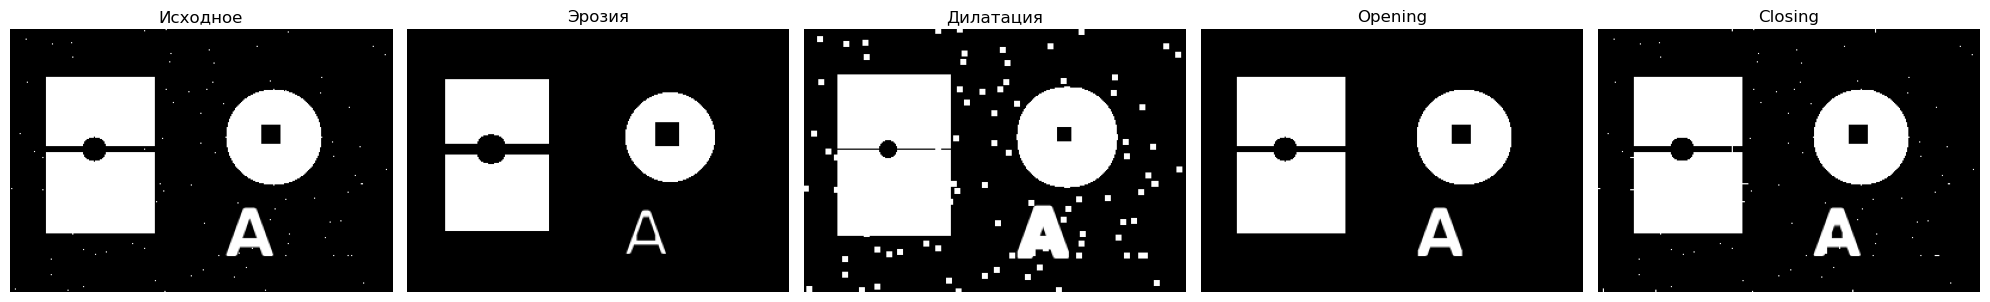

In [19]:
compare_morphology(binary_demo, kernel_rect)

### 8. Сравнение разных ядер
Форма структурирующего элемента влияет на результат обработки. Прямоугольное ядро обычно действует более жёстко, эллиптическое — мягче для округлых объектов, а крестообразное может лучше сохранять тонкие направления по вертикали и горизонтали.

In [20]:
def compare_kernels(binary_img, operation="open", ksize=(5, 5)):
    kernels = {
        "RECT": cv2.getStructuringElement(cv2.MORPH_RECT, ksize),
        "ELLIPSE": cv2.getStructuringElement(cv2.MORPH_ELLIPSE, ksize),
        "CROSS": cv2.getStructuringElement(cv2.MORPH_CROSS, ksize),
    }

    results = []
    titles = ["Исходное"]

    results.append(binary_img)

    for name, kernel in kernels.items():
        if operation == "erode":
            result = cv2.erode(binary_img, kernel, iterations=1)
        elif operation == "dilate":
            result = cv2.dilate(binary_img, kernel, iterations=1)
        elif operation == "open":
            result = cv2.morphologyEx(binary_img, cv2.MORPH_OPEN, kernel)
        elif operation == "close":
            result = cv2.morphologyEx(binary_img, cv2.MORPH_CLOSE, kernel)
        else:
            raise ValueError("Неизвестная операция")

        results.append(result)
        titles.append(f"{operation.upper()} + {name}")

    fig, axes = plt.subplots(1, 4, figsize=(18, 4))
    for ax, img, title in zip(axes, results, titles):
        ax.imshow(img, cmap='gray')
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

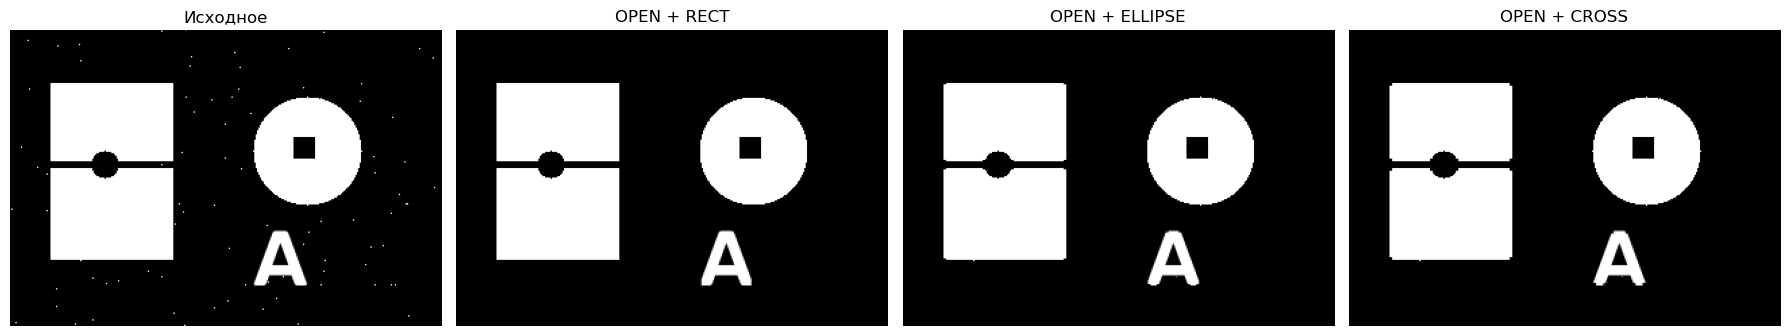

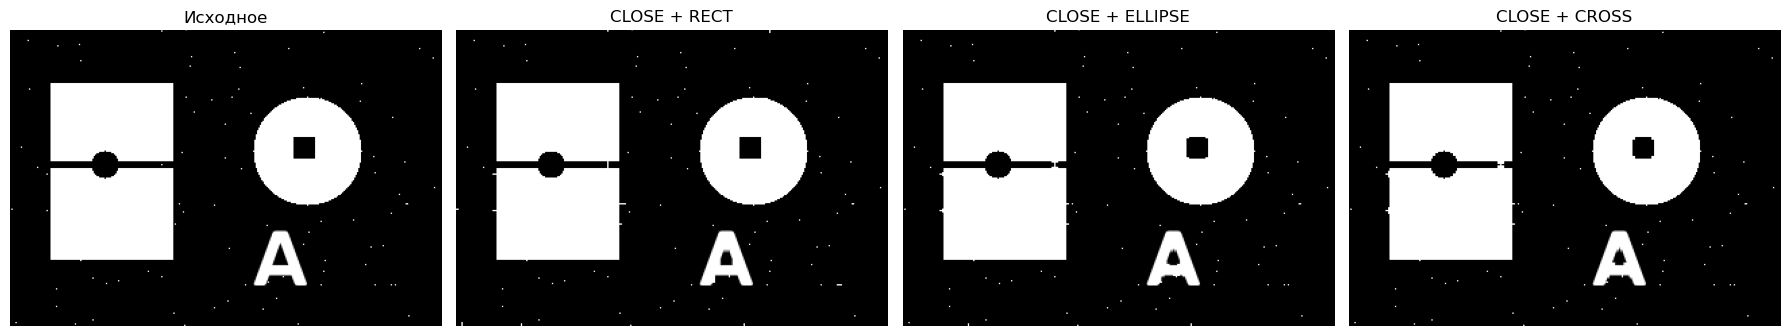

In [21]:
compare_kernels(binary_demo, operation="open", ksize=(5, 5))
compare_kernels(binary_demo, operation="close", ksize=(5, 5))

После бинаризации изображение часто всё ещё содержит дефекты: одиночные шумовые точки, разрывы, небольшие отверстия, слипшиеся или слишком тонкие области. Морфологические операции нужны именно для того, чтобы привести бинарную маску в форму, удобную для практических алгоритмов — поиска контуров, распознавания текста, выделения связных компонентов и измерения объектов.

С практической точки зрения связь между шагами выглядит так:
* Исходное изображение переводится в полутоновое.
* Выполняется бинаризация.
* Полученная маска очищается морфологическими операциями.
* Уже после этого выполняются контурный анализ, OCR, сегментация объектов или измерения.

**Задание 1**

Возьмите бинарное изображение binary_demo и примените к нему операции opening и closing с тремя типами ядер:

* cv2.MORPH_RECT
* cv2.MORPH_ELLIPSE
* cv2.MORPH_CROSS

Сравните результаты визуально и ответьте:

* Какое ядро лучше удаляет одиночные шумовые точки?
* Какое ядро лучше сохраняет форму круглых объектов?
* Какое ядро лучше соединяет разрывы в символах и линиях?

**Задание 2**

Измените размер ядра: (3, 3), (5, 5), (9, 9) и исследуйте, как меняется результат opening и closing. Сделайте вывод о влиянии размера структурирующего элемента на степень сглаживания и искажения формы объектов.

**Задание 3**

Загрузите реальное изображение, выполните:
* перевод в GRAY;
* бинаризацию;
* opening для удаления шума;
* closing для заполнения разрывов.

Сохраните все промежуточные результаты в отдельную папку и кратко опишите, какой шаг оказался наиболее важным.

## Контуры и анализ объектов
После бинаризации и морфологической обработки изображение становится пригодным для выделения отдельных объектов. На практике это нужно для подсчёта объектов, измерения их площади, определения положения, выделения границ и формирования признаков формы для дальнейшего анализа.

Зачем это нужно на практике?
Переход к контурам — это следующий шаг после получения качественной бинарной маски. Если раньше задача состояла в том, чтобы отделить объект от фона, то теперь задача — извлечь геометрическую информацию об этом объекте: где он находится, каков его размер, насколько он вытянут, сколько объектов присутствует на изображении.

С практической точки зрения это используется в таких задачах:
* Подсчёт деталей на конвейере.
* Измерение площади объектов на микроскопических или медицинских изображениях.
* Поиск символов и областей текста после бинаризации документов.
* Выделение объектов интереса перед классификацией или трекингом.
* Фильтрация шумовых компонент по площади и размеру ограничивающего прямоугольника.

### 1. Подготовка тестового изображения
Создадим синтетическое бинарное изображение с несколькими объектами и небольшим шумом. Это позволит отработать поиск контуров в полностью контролируемом примере.

In [22]:
def create_contour_demo_image():
    """
    Создает бинарное изображение с несколькими объектами и шумом.
    """
    img = np.zeros((260, 420), dtype=np.uint8)

    # Основные объекты
    cv2.rectangle(img, (30, 40), (120, 180), 255, -1)
    cv2.circle(img, (220, 100), 45, 255, -1)
    cv2.ellipse(img, (330, 160), (50, 25), 20, 0, 360, 255, -1)
    cv2.putText(img, "8", (180, 220),
                cv2.FONT_HERSHEY_SIMPLEX, 2, 255, 4)

    # Небольшой шум
    np.random.seed(7)
    for _ in range(80):
        x = np.random.randint(0, img.shape[1])
        y = np.random.randint(0, img.shape[0])
        img[y, x] = 255

    return img

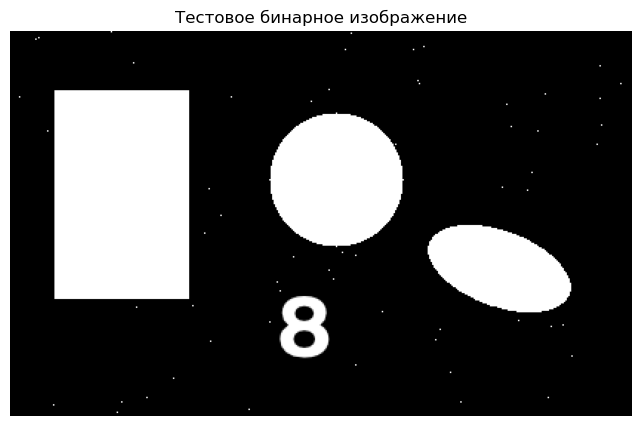

In [23]:
binary_objects = create_contour_demo_image()

plt.figure(figsize=(9, 5))
plt.imshow(binary_objects, cmap='gray')
plt.title("Тестовое бинарное изображение")
plt.axis("off")
plt.show()

### 2. Морфологическая очистка перед поиском контуров
Перед поиском контуров полезно удалить мелкие шумовые компоненты. Для этого удобно использовать `opening`, так как он убирает небольшие белые шумовые точки, сохраняя основные объекты.

In [24]:
def clean_binary_for_contours(binary_img, ksize=(3, 3)):
    """
    Удаляет мелкий шум перед поиском контуров.
    """
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, ksize)
    cleaned = cv2.morphologyEx(binary_img, cv2.MORPH_OPEN, kernel)
    return cleaned

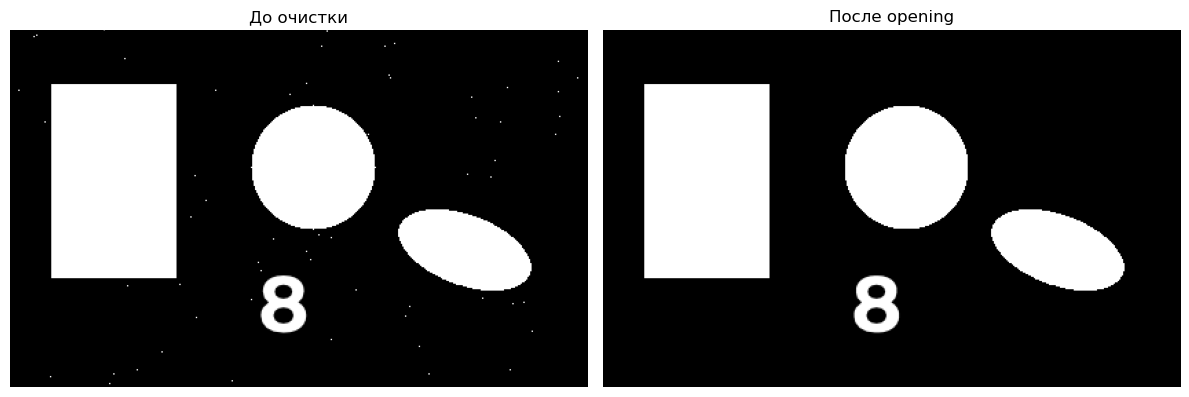

In [25]:
binary_clean = clean_binary_for_contours(binary_objects, ksize=(3, 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(binary_objects, cmap='gray')
axes[0].set_title("До очистки")
axes[0].axis("off")

axes[1].imshow(binary_clean, cmap='gray')
axes[1].set_title("После opening")
axes[1].axis("off")

plt.tight_layout()
plt.show()

### 3. Поиск контуров
Контуры в OpenCV — это непрерывные границы объектов на бинарном изображении. Для их поиска используется функция `cv2.findContours`, причём перед ней обычно рекомендуют выполнять бинаризацию или выделение границ, так как контурный анализ работает точнее именно на бинарных изображениях.

In [26]:
def find_and_draw_contours(binary_img):
    """
    Ищет контуры и рисует их на цветной копии изображения.
    """
    contours, hierarchy = cv2.findContours(
        binary_img.copy(),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    contour_vis = cv2.cvtColor(binary_img, cv2.COLOR_GRAY2BGR)
    cv2.drawContours(contour_vis, contours, -1, (0, 255, 0), 2)

    return contours, contour_vis

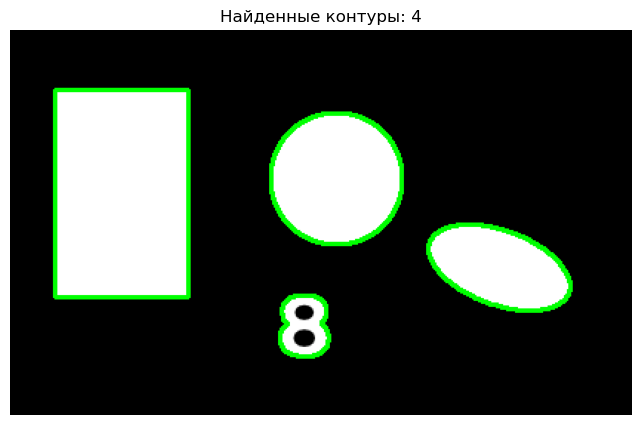

In [27]:
contours, contour_vis = find_and_draw_contours(binary_clean)

plt.figure(figsize=(9, 5))
plt.imshow(cv2.cvtColor(contour_vis, cv2.COLOR_BGR2RGB))
plt.title(f"Найденные контуры: {len(contours)}")
plt.axis("off")
plt.show()

### 4. Площадь контура
Одной из самых важных характеристик объекта является его площадь. В `OpenCV` она вычисляется функцией `cv2.contourArea`, что позволяет фильтровать слишком маленькие контуры и выделять значимые объекты.

In [28]:
def print_contour_areas(contours):
    """
    Выводит площади всех найденных контуров.
    """
    for i, cnt in enumerate(contours, start=1):
        area = cv2.contourArea(cnt)
        print(f"Контур {i}: площадь = {area:.2f}")

In [29]:
print_contour_areas(contours)

Контур 1: площадь = 1122.00
Контур 2: площадь = 3931.00
Контур 3: площадь = 6230.00
Контур 4: площадь = 12600.00


### 5. Ограничивающий прямоугольник
Для локализации объекта часто используют ограничивающий прямоугольник. В `OpenCV` его можно получить функцией `cv2.boundingRect`, которая возвращает координаты верхнего левого угла и размеры прямоугольника.

In [30]:
def draw_bounding_boxes(binary_img, contours, min_area=50):
    """
    Рисует ограничивающие прямоугольники вокруг объектов.
    """
    vis = cv2.cvtColor(binary_img, cv2.COLOR_GRAY2BGR)

    for cnt in contours:
        area = cv2.contourArea(cnt)
        if area < min_area:
            continue

        x, y, w, h = cv2.boundingRect(cnt)
        cv2.rectangle(vis, (x, y), (x + w, y + h), (255, 0, 0), 2)

    return vis

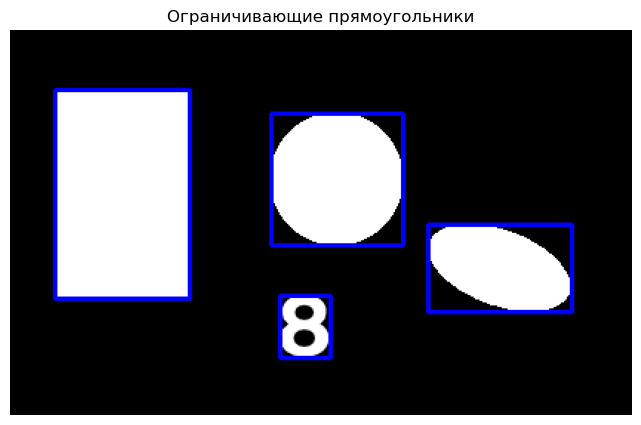

In [31]:
boxes_vis = draw_bounding_boxes(binary_clean, contours, min_area=100)

plt.figure(figsize=(9, 5))
plt.imshow(cv2.cvtColor(boxes_vis, cv2.COLOR_BGR2RGB))
plt.title("Ограничивающие прямоугольники")
plt.axis("off")
plt.show()

### 6. Центр объекта
Для многих прикладных задач важно знать положение объекта. Один из простых вариантов — найти центр масс контура через геометрические моменты с помощью `cv2.moments`.

In [32]:
def draw_object_centers(binary_img, contours, min_area=50):
    """
    Вычисляет и отображает центры объектов.
    """
    vis = cv2.cvtColor(binary_img, cv2.COLOR_GRAY2BGR)

    for i, cnt in enumerate(contours, start=1):
        area = cv2.contourArea(cnt)
        if area < min_area:
            continue

        M = cv2.moments(cnt)
        if M["m00"] == 0:
            continue

        cx = int(M["m10"] / M["m00"])
        cy = int(M["m01"] / M["m00"])

        cv2.circle(vis, (cx, cy), 4, (0, 0, 255), -1)
        cv2.putText(vis, str(i), (cx + 5, cy - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1)

    return vis

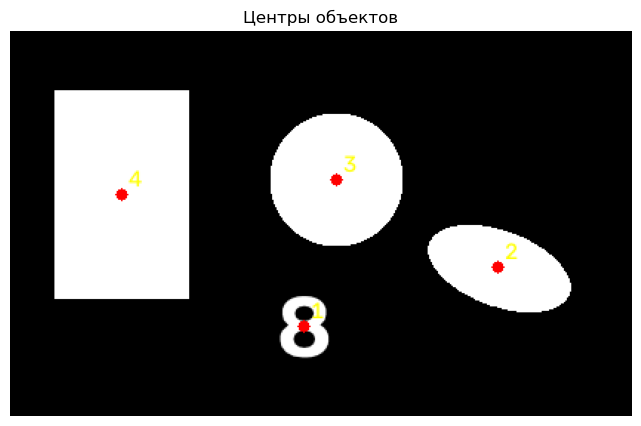

In [33]:
centers_vis = draw_object_centers(binary_clean, contours, min_area=100)

plt.figure(figsize=(9, 5))
plt.imshow(cv2.cvtColor(centers_vis, cv2.COLOR_BGR2RGB))
plt.title("Центры объектов")
plt.axis("off")
plt.show()

### 7. Полный анализ объектов
Полезно объединить несколько шагов в одну функцию, которая находит контуры, фильтрует шум по площади и выводит ключевые характеристики объектов. Такой формат ближе к реальному практическому пайплайну анализа изображений.

In [34]:
def analyze_objects(binary_img, min_area=100):
    """
    Выполняет поиск объектов и выводит их базовые характеристики:
    площадь, bounding box, центр.
    """
    contours, hierarchy = cv2.findContours(
        binary_img.copy(),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    vis = cv2.cvtColor(binary_img, cv2.COLOR_GRAY2BGR)
    object_count = 0

    for cnt in contours:
        area = cv2.contourArea(cnt)
        if area < min_area:
            continue

        object_count += 1
        x, y, w, h = cv2.boundingRect(cnt)

        M = cv2.moments(cnt)
        if M["m00"] != 0:
            cx = int(M["m10"] / M["m00"])
            cy = int(M["m01"] / M["m00"])
        else:
            cx, cy = x + w // 2, y + h // 2

        cv2.drawContours(vis, [cnt], -1, (0, 255, 0), 2)
        cv2.rectangle(vis, (x, y), (x + w, y + h), (255, 0, 0), 2)
        cv2.circle(vis, (cx, cy), 4, (0, 0, 255), -1)

        print(
            f"Объект {object_count}: "
            f"area={area:.2f}, bbox=({x}, {y}, {w}, {h}), center=({cx}, {cy})"
        )

    print(f"\nВсего объектов после фильтрации: {object_count}")
    return vis

Объект 1: area=1122.00, bbox=(182, 179, 34, 42), center=(198, 199)
Объект 2: area=3931.00, bbox=(282, 131, 97, 59), center=(329, 159)
Объект 3: area=6230.00, bbox=(176, 56, 89, 89), center=(220, 100)
Объект 4: area=12600.00, bbox=(30, 40, 91, 141), center=(75, 110)

Всего объектов после фильтрации: 4


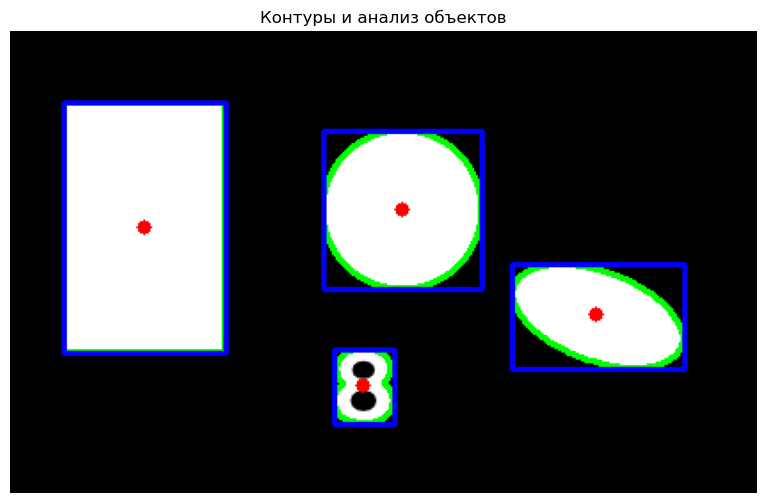

In [35]:
analysis_vis = analyze_objects(binary_clean, min_area=100)

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(analysis_vis, cv2.COLOR_BGR2RGB))
plt.title("Контуры и анализ объектов")
plt.axis("off")
plt.show()

Контур — это граница связной области, а не просто “линия на картинке”. Именно поэтому качественный поиск контуров требует хорошей бинарной маски, а значит опирается на предыдущие этапы: пороговую обработку и морфологическую очистку.

На практике цепочка выглядит так:
* Исходное изображение переводится в полутоновое.
* Выполняется бинаризация.
* Бинарная маска очищается морфологическими операциями.
* На очищенной маске ищутся контуры.
* Для найденных объектов вычисляются площадь, положение и ограничивающие прямоугольники.

Такой пайплайн нужен в реальных системах контроля качества, для анализа документов, медицинских изображений и в простых системах машинного зрения на производстве.

**Задание 1**

Измените порог фильтрации `min_area` в функции `analyze_objects` и проследите, как меняется число найденных объектов. Объясните, почему слишком маленький порог приводит к учёту шумовых компонентов, а слишком большой — к потере полезных объектов.

**Задание 2**

Добавьте в анализ вычисление периметра объекта с помощью `cv2.arcLength`. Сравните объекты по площади и периметру и сделайте вывод, какие из них более компактны.

**Задание 3**

Примените описанный пайплайн к реальному изображению:
* перевод в GRAY;
* бинаризация;
* морфология;
* поиск контуров;
* построение ограничивающих прямоугольников.

Сохраните итоговое изображение и кратко опишите качество выделения объектов.

**Задание 4**

Сравните два подхода:
* анализ через `cv2.findContours`;
* анализ через `cv2.connectedComponentsWithStats`.

Определите, в каком случае удобнее работать с контурами, а в каком — со связными компонентами, поскольку `connectedComponentsWithStats` позволяет получать статистику по компонентам, включая bounding box, площадь и координаты центра.